# MAESTER: Fig. 3 and Supplementary Fig. S3

Every result of the MAESTER analysis in the paper, computed from the deposited data and fit. Run from top to bottom.

- Data: `data/h5ad_files_RNA/rna_exp.h5ad` (expression and cell types; preprocessing in `preprocess/MAESTER/`).
- Fit: `output/v2/maester/202610/11/085606` (seed 2024), trained by `retrain/train_maester.py`. `cloneVI_result.h5ad` holds all cells, `cloneVI_test_result.h5ad` the test cells.
- Output: `analysis/results/maester/`, one PDF per panel, Fig. 3 and Supplementary Fig. S3 assembled from them, and the tables below as CSV.

In [1]:
%cd ../src

.../cloneVI/src


.../site-packages/IPython/core/magics/osm.py:417: UserWarning: This is now an optional IPython functionality, setting dhist requires you to install the `pickleshare` library.
  self.shell.db['dhist'] = compress_dhist(dhist)[-100:]


In [2]:
import os
import ast
import re

import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import seaborn as sns
from matplotlib.lines import Line2D
from adjustText import adjust_text
from scipy.stats import pearsonr, rankdata, spearmanr
from sklearn.metrics import roc_auc_score
from sklearn.neighbors import NearestNeighbors

In [3]:
RNA = '../data/h5ad_files_RNA/rna_exp.h5ad'
RUN = '../output/v2/maester/202610/11/085606'
OUT = '../analysis/results/maester'
os.makedirs(OUT, exist_ok=True)

### Figure style

The same in every notebook of the paper. Panels are drawn at their print size, so that text and points match in the assembled figures. Every UMAP panel has the same size and frame. Colours of the UMAP panels as in the original analysis notebooks: clonal probability and VAF in cubehelix maps (from 0 to the largest value of the panel), two clones in the end colours of viridis, expression in viridis. Heatmaps keep the colour maps of the original notebooks (for $\phi$ the seaborn default).

In [4]:
plt.rcParams.update({'font.size': 6.5, 'axes.titlesize': 7, 'axes.labelsize': 6.5, 'xtick.labelsize': 6,
                     'ytick.labelsize': 6, 'legend.fontsize': 6, 'axes.linewidth': 0.5, 'xtick.major.width': 0.5,
                     'ytick.major.width': 0.5, 'xtick.major.size': 2, 'ytick.major.size': 2, 'savefig.dpi': 600})
PI_CMAP = sns.cubehelix_palette(start=.5, rot=-.5, as_cmap=True)
VAF_CMAP = sns.cubehelix_palette(as_cmap=True)
EXPR_CMAP = 'viridis'
MAP_SIZE = (2.0, 1.6)    # inches, every UMAP panel: map 1.36 in wide, colour bar or legend on the right


def new_map():
    fig = plt.figure(figsize=MAP_SIZE)
    ax = fig.add_axes([0.01, 0.02, 0.68, 0.84])
    ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_visible(False)
    return fig, ax


def map_values(xy, v, cmap, title, label, s, vmin=0, vmax=None):
    # continuous values, high values drawn on top
    fig, ax = new_map()
    vmax = float(np.max(v)) if vmax is None else vmax
    o = np.argsort(v)
    ax.scatter(xy[o, 0], xy[o, 1], c=v[o], cmap=cmap, vmin=vmin, vmax=vmax, s=s, linewidths=0, rasterized=RASTER)
    ax.set_aspect('equal', adjustable='datalim')
    cb = fig.colorbar(plt.cm.ScalarMappable(plt.Normalize(vmin, vmax), cmap), cax=fig.add_axes([0.72, 0.12, 0.03, 0.62]))
    cb.outline.set_visible(False)
    cb.set_label(label)
    ax.set_title(title)
    return fig, ax


def map_groups(xy, groups, colors, title, s, labels=None, on_data=False, legend=True, seed=0):
    # categories, cells drawn in a fixed random order so that no group hides another
    fig, ax = new_map()
    o = np.random.default_rng(seed).permutation(len(groups))
    ax.scatter(xy[o, 0], xy[o, 1], c=[colors[g] for g in groups[o]], s=s, linewidths=0, rasterized=RASTER)
    ax.set_aspect('equal', adjustable='datalim')
    labels = labels or {g: str(g) for g in colors}
    if on_data:
        for g in colors:
            x, y = np.median(xy[groups == g], axis=0)
            ax.text(x, y, labels[g], ha='center', va='center', fontweight='bold',
                    path_effects=[pe.withStroke(linewidth=1.5, foreground='white')])
    elif legend:
        ax.legend(handles=legend_handles(colors, labels), loc='center left', bbox_to_anchor=(1.0, 0.5), frameon=False,
                  handletextpad=0.1)
    ax.set_title(title)
    return fig, ax


def legend_handles(colors, labels):
    return [Line2D([], [], marker='o', ls='', markersize=3, color=colors[g], label=labels[g]) for g in colors]


def legend_panel(colors, labels, ncol=1):
    # a legend as its own panel, for maps with many groups
    fig, ax = plt.subplots(figsize=(0.5, 0.5))
    ax.axis('off')
    ax.legend(handles=legend_handles(colors, labels), loc='center', ncol=ncol, frameon=False, handletextpad=0.1,
              columnspacing=1.0)
    return fig


def save(fig, name):
    # maps keep their fixed size; other panels are cropped to their content
    fixed = fig.get_size_inches().tolist() == list(MAP_SIZE)
    fig.savefig(f'{OUT}/{name}.pdf', bbox_inches=None if fixed else 'tight')

In [5]:
S = 0.6                                 # point size of the UMAP panels (9,346 cells)
RASTER = True                           # points rasterized at 600 dpi, text and axes stay vector
CT_NAMES = {0: 'Hematopoietic stem cell', 1: 'Progenitor', 2: 'Early erythroid', 3: 'Late erythroid',
            4: 'Promonocyte', 5: 'Monocyte', 6: 'Nonclassical monocyte', 7: 'Conventional DC', 8: 'Plasmacytoid DC',
            9: 'B cell', 10: 'Plasma cell', 11: 'T cell', 12: 'CTL', 13: 'NK cell'}
HL_VARIANTS = {'683': '#D55E00', '9164': '#0072B2', '779': '#009E73'}   # their clones (HL, set after the fit is read) are shown
                                                                       # in Fig. 3c-d; their variants are coloured in Fig. 3e-f
den = lambda M: M.toarray() if sp.issparse(M) else np.asarray(M)

## 1. The data and the fit

In [6]:
rna = sc.read_h5ad(RNA)                                   # raw counts in .raw, cell types in obs['CellType']
adata_mg = sc.read_h5ad(f'{RUN}/cloneVI_result.h5ad')     # all cells: X = depth, layers VAF / all_mut, pi, phi, z
test_mg = sc.read_h5ad(f'{RUN}/cloneVI_test_result.h5ad') # test cells
adata_mg

AnnData object with n_obs × n_vars = 9346 × 26
    obs: 'barcode', 'genotype'
    var: 'seqnames', 'start', 'end', 'width', 'refAllele'
    uns: 'alpha'
    obsm: 'X_cloneVI_umap', 'pi_deleted', 'pi_sorted', 'z'
    varm: 'phi_0', 'phi_deleted', 'phi_k', 'phi_sorted', 'phi_specific'
    layers: 'VAF', 'all_mut', 'reconst_VAF'

Raw counts with the gene names of the expression data (`rna.raw` keeps the counts but numbers the genes).

In [7]:
def raw_counts(cells=None):
    a = sc.AnnData(rna.raw.X.copy(), obs=rna.obs.copy(), var=rna.var.copy())
    return a if cells is None else a[cells].copy()

The cells of the fit, in the same order as their barcodes in the expression data.

In [8]:
idx = pd.Index(rna.obs_names).get_indexer(adata_mg.obs['barcode'].to_numpy())
celltype = rna.obs['CellType'].astype(int).map(CT_NAMES).to_numpy()[idx]
adata_mg.n_obs, test_mg.n_obs, bool((idx >= 0).all())

(9346, 934, True)

### Settings of the fit

Recorded by the run. `lmd_pi` and `lmd_phi` are recorded, but no regularization stage was run (`use_sparse_term` is False). The allele frequency is not decomposed into a shared and a clone-specific part in this fit (`use_phi_common` is False; the stored `phi_0` and `alpha` are zero): the MAESTER data have no background variant carried by most cells (`retrain/README.md`).

In [9]:
params = {}
for line in open(f'{RUN}/used_parameters.txt'):
    key, value = line.rstrip('\n').split(': ', 1)
    try:
        params[key] = ast.literal_eval(value)
    except (ValueError, SyntaxError):
        params[key] = value
fit = pd.Series({'model input (cells, genes)': params['adata_shape'], 'variants': len(params['model_params']['mutations']),
                 'K (candidate clones)': params['model_params']['k'], 'validation / test fraction':
                 (params['val_ratio'], params['test_ratio']), 'regularization stage': params['use_sparse_term'],
                 'phi decomposition': params['model_params'].get('use_phi_common', True), 'seed': params['seed']}, dtype=object)   # use_phi_common not recorded: code before 2026-06 always decomposed
fit

model input (cells, genes)    (9346, 2000)
variants                                26
K (candidate clones)                    20
validation / test fraction     (0.05, 0.1)
regularization stage                 False
phi decomposition                    False
seed                                  2024
dtype: object

The model input (Methods): cells with at least 200 detected genes, genes detected in at least 3 cells, and the raw counts of the 2,000 most variable genes after normalization. The same steps give the input shape recorded above.

In [10]:
x_in = raw_counts()
sc.pp.filter_cells(x_in, min_genes=200)
sc.pp.filter_genes(x_in, min_cells=3)
sc.pp.normalize_total(x_in, target_sum=1e4)
sc.pp.log1p(x_in)
sc.pp.highly_variable_genes(x_in, n_top_genes=2000)
int(x_in.n_obs), int(x_in.var['highly_variable'].sum())

.../site-packages/scanpy/preprocessing/_highly_variable_genes.py:215: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  disp_grouped = df.groupby('mean_bin')['dispersions']


(9346, 2000)

### Pruned clones

A clone is kept if its mean $\pi$ exceeds 0.01 or its largest $\pi$ is at least 0.2 (Methods). Of the 20 candidate clones, six are kept and renumbered 0–5.

In [11]:
pi_all = np.asarray(adata_mg.obsm['pi_sorted'], dtype=float)
pruning = pd.DataFrame({'mean pi': pi_all.mean(0), 'max pi': pi_all.max(0)})
pruning['kept'] = (pruning['mean pi'] > 0.01) | (pruning['max pi'] >= 0.2)
pruning.round(4)

,mean pi,max pi,kept
0,0.8928,0.9982,True
1,0.0208,0.1505,True
2,0.0169,0.4400,True
3,0.0146,0.6183,True
4,0.0081,0.2830,True
5,0.0072,0.0744,False
6,0.0055,0.0443,False
7,0.0050,0.1423,False
8,0.0045,0.0235,False
9,0.0042,0.7831,True


In [12]:
pi = np.asarray(adata_mg.obsm['pi_deleted'], dtype=float)
phi = np.asarray(adata_mg.varm['phi_deleted'], dtype=float)      # variants x clones
variants = np.array([str(v) for v in adata_mg.var_names])
pi.shape, phi.shape

((9346, 6), (26, 6))

The variants each kept clone carries ($\phi > 0.2$). Clone 0 carries none: it is the background clone.

In [13]:
carried = pd.Series({k: ', '.join(f'{variants[j]} ({phi[j, k]:.2f})' for j in np.flatnonzero(phi[:, k] > 0.2))
                     for k in range(phi.shape[1])}, name='variants (phi)')
carried

0                            
1                  683 (0.96)
2                 2593 (0.63)
3    6205 (0.84), 9164 (1.00)
4    9321 (0.62), 3988 (0.32)
5                  779 (0.59)
Name: variants (phi), dtype: object

In [14]:
CARRIED = {k: list(variants[phi[:, k] > 0.2]) for k in range(phi.shape[1]) if (phi[:, k] > 0.2).any()}
VARIANT_CLONE = {m: int(phi[j].argmax()) for j, m in enumerate(variants) if phi[j].max() > 0.2}   # the clone with the largest phi
HL = {VARIANT_CLONE[m]: c for m, c in HL_VARIANTS.items()}   # Clones 1, 3 and 5 (683, 6205 + 9164, 779)
CARRIED, HL

({1: ['683'],
  2: ['2593'],
  3: ['6205', '9164'],
  4: ['9321', '3988'],
  5: ['779']},
 {1: '#D55E00', 3: '#0072B2', 5: '#009E73'})

## 2. Fig. 3a: cell types on the CloneVI UMAP

The UMAP of the cell state $z$ inferred by CloneVI, coloured by the cell types of the original study.

In [15]:
xy = adata_mg.obsm['X_cloneVI_umap']
cats = [c for c in CT_NAMES.values() if c in set(celltype)]
ct_col = dict(zip(cats, plt.get_cmap('tab20')(np.arange(len(cats)) % 20)))
pd.Series(celltype).value_counts()[cats]

Hematopoietic stem cell      15
Progenitor                   18
Early erythroid             117
Late erythroid               62
Promonocyte                  25
Monocyte                    110
Nonclassical monocyte        30
Conventional DC             126
Plasmacytoid DC              51
B cell                      158
Plasma cell                  19
T cell                     2252
CTL                        6130
NK cell                     233
Name: count, dtype: int64

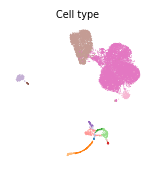

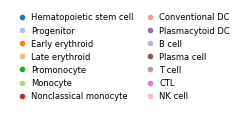

In [16]:
fig, ax = map_groups(xy, celltype, ct_col, 'Cell type', S, legend=False)
save(fig, 'fig3a_celltype')
fig = legend_panel(ct_col, {c: c for c in cats}, ncol=2)
save(fig, 'fig3a_legend')

## 3. Fig. 3b: clone-specific allele frequencies $\phi$

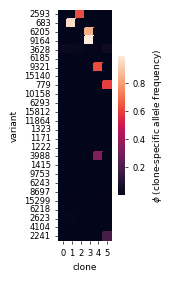

In [17]:
fig, ax = plt.subplots(figsize=(1.6, 3.0))
sns.heatmap(phi, yticklabels=variants, xticklabels=range(phi.shape[1]), square=True, ax=ax, linewidths=0.3,
            linecolor='face', cbar_kws={'label': r'$\phi$ (clone-specific allele frequency)', 'shrink': 0.6})
ax.tick_params(length=2)
ax.set_xlabel('clone')
ax.set_ylabel('variant')
save(fig, 'fig3b_phi')

## 4. Fig. 3c and Supplementary Fig. S3a: clonal probabilities and the VAF of the variants each clone carries

For every kept clone, $\pi$ (Fig. 3c shows Clones 1, 3 and 5, Supplementary Fig. S3a all six); for every clone that carries variants, the observed VAF of those variants (the mean when there are two). Clone 0 carries none. Cells without reads at a variant have VAF 0.

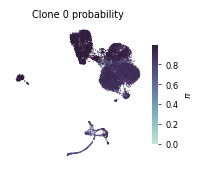

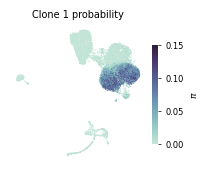

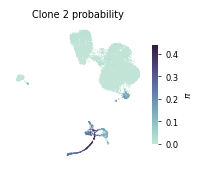

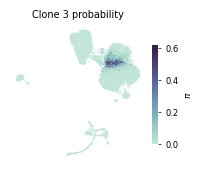

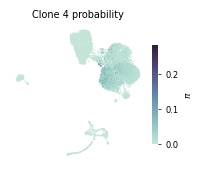

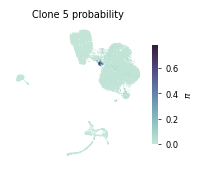

In [18]:
vaf = den(adata_mg.layers['VAF']).astype(float)
for k in range(pi.shape[1]):
    fig, ax = map_values(xy, pi[:, k], PI_CMAP, f'Clone {k} probability', r'$\pi$', S)
    save(fig, f'pi_clone{k}')

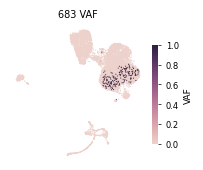

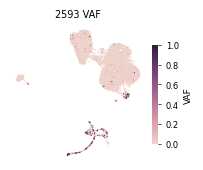

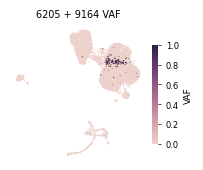

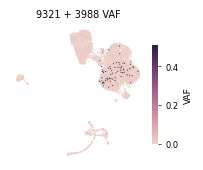

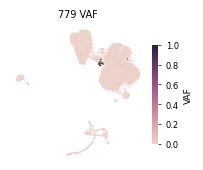

In [19]:
for k, muts in CARRIED.items():
    J = [list(variants).index(m) for m in muts]
    fig, ax = map_values(xy, vaf[:, J].mean(1), VAF_CMAP, ' + '.join(muts) + ' VAF', 'VAF', S)
    save(fig, f'vaf_clone{k}')

## 5. Fig. 3d: the TCR gene of each clone

For every kept clone (Fig. 3d shows Clones 1, 3 and 5).

Expression for the downstream analysis (Methods): genes detected in at least 20 cells, log-normalized, the 4,000 most variable genes, each divided by its mean over cells.

In [20]:
adata = raw_counts(idx)
adata.var_names_make_unique()
adata.X = adata.X.toarray()
sc.pp.filter_cells(adata, min_genes=200)
sc.pp.filter_genes(adata, min_cells=20)
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
sc.pp.highly_variable_genes(adata, n_top_genes=4000)
adata = adata[:, adata.var['highly_variable']].copy()
adata.X = adata.X / adata.X.mean(axis=0)
assert (adata.obs_names == adata_mg.obs['barcode'].to_numpy()).all()
adata

.../site-packages/scanpy/preprocessing/_highly_variable_genes.py:215: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  disp_grouped = df.groupby('mean_bin')['dispersions']


AnnData object with n_obs × n_vars = 9346 × 4000
    obs: 'nCount_RNA', 'nFeature_RNA', 'replicate', 'CellType', 'project.umap.x', 'project.umap.y', 'TET2.S792*', 'TET2.Q1034*', 'TET2.R1216*', 'TET2.H1380Y', 'ACAP2.L97M', 'ASXL1.G642fs', 'CWF19L2.K221R', 'DOLPP1.R227S', 'HNRNPUL1.F559F', 'MAP4K5.P667S', 'RAB9A.3pUTR', 'MTAP.rearr', 'BPDCN_Tumor_score', 'Cycle_score', 'UMAP_1', 'UMAP_2', 'UMAP_TNK_1', 'UMAP_TNK_2', 'TNK_CellType', 'TRB_CDR3', 'TRA_CDR3', 'MT_clone', 'MT_clone_num', 'n_genes'
    var: 'features', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'log1p', 'hvg'

The $\pi$-weighted mean expression of gene $g$ in clone $k$, $s_{gk} = \sum_c x_{gc}\pi_{ck} / \sum_c \pi_{ck}$ (Methods), and for each clone the TCR variable-region genes (TRAV, TRBV, TRGV, TRDV) with the highest $s_{gk}$.

In [21]:
s_gk = pd.DataFrame((adata.X.T @ pi) / pi.sum(0), index=adata.var_names)
is_tcr_v = s_gk.index.str.match(r'^TR[ABGD]V')
tcr_top = pd.concat({f'Clone {k}': s_gk.loc[is_tcr_v, k].sort_values(ascending=False).head(5).reset_index()
                     .set_axis(['gene', 's_gk'], axis=1) for k in range(pi.shape[1])}, axis=1)
tcr_top.round(2)

Clone 0            Clone 1          Clone 2         Clone 3         \
        gene  s_gk         gene  s_gk       gene  s_gk      gene   s_gk   
0      TRAV3  1.10        TRDV1  2.96      TRDV2  0.81   TRBV7-9  11.19   
1  TRAV23DV6  1.10     TRBV12-3  2.87      TRGV7  0.40  TRBV29-1   3.93   
2  TRAV36DV7  1.09  TRAV38-2DV8  2.85      TRGV9  0.34     TRAV5   3.71   
3    TRBV3-1  1.07        TRGV9  2.48   TRBV20-1  0.28  TRBV21-1   3.41   
4   TRBV20-1  1.07        TRGV2  2.44  TRAV36DV7  0.25    TRBV15   3.35   

  Clone 4       Clone 5         
     gene  s_gk    gene   s_gk  
0   TRGV8  2.55   TRDV2  80.26  
1  TRGV11  2.34   TRGV9   6.00  
2  TRAV30  2.32   TRGV8   4.02  
3  TRGV10  2.20   TRGV7   2.42  
4   TRDV2  1.99  TRBV19   2.08

In [22]:
TCR_GENE = {k: s_gk.loc[is_tcr_v, k].idxmax() for k in range(pi.shape[1])}
TCR_GENE

{0: 'TRAV3', 1: 'TRDV1', 2: 'TRDV2', 3: 'TRBV7-9', 4: 'TRGV8', 5: 'TRDV2'}

The panels show the log-normalized expression of all cells (colour scale up to the 99th percentile of the expressing cells).

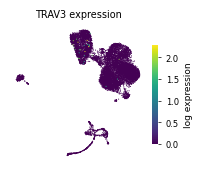

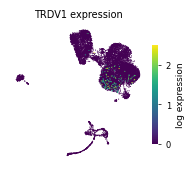

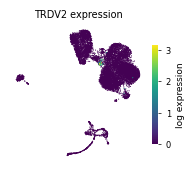

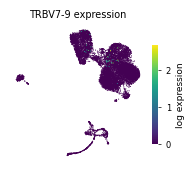

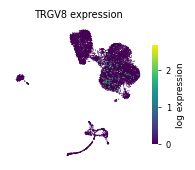

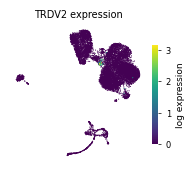

In [23]:
expr = raw_counts(idx)
expr.var_names_make_unique()
sc.pp.normalize_total(expr, target_sum=1e4)
sc.pp.log1p(expr)
for k, gene in TCR_GENE.items():
    v = den(expr[:, gene].X).ravel()
    fig, ax = map_values(xy, v, EXPR_CMAP, f'{gene} expression', 'log expression', S, vmax=np.quantile(v[v > 0], 0.99))
    save(fig, f'tcr_clone{k}_{gene}')

## 6. Fig. 3e: VAF of the test cells

The test cells were not used for training. For each test cell and variant, the reconstructed VAF $\sum_k \pi_{ck}\phi_{km}$ uses all 20 clones of the fit (this compares prediction accuracy, so the pruned clones are kept; Methods); it is set to 0 where the cell has no reads, as the observed VAF. The baseline gives each test cell the mean VAF of its cell type in the cells outside the test set (training and validation cells). Agreement with the observed VAF: Pearson $r$ per variant (0 when a variant has no variation in the test cells).

In [24]:
assert (test_mg.var_names == adata_mg.var_names).all()
depth_te = den(test_mg.X).astype(float)
vaf_te = den(test_mg.layers['VAF']).astype(float)
recon_te = np.asarray(test_mg.obsm['pi_sorted']) @ np.asarray(test_mg.varm['phi_sorted']).T
recon_te = np.where(depth_te > 0, recon_te, 0.0)

outside = ~adata_mg.obs['barcode'].isin(test_mg.obs['barcode']).to_numpy()
ct_by_bc = dict(zip(adata_mg.obs['barcode'], celltype))
ct_te = test_mg.obs['barcode'].map(ct_by_bc).to_numpy()
base_te = np.zeros_like(vaf_te)
for c in np.unique(ct_te):
    m = outside & (celltype == c)
    base_te[ct_te == c] = vaf[m].mean(0) if m.any() else vaf[outside].mean(0)
int(outside.sum()), len(ct_te)

(8412, 934)

In [25]:
r0 = lambda a, b: 0.0 if np.std(a) == 0 or np.std(b) == 0 else pearsonr(a, b)[0]
rec = pd.DataFrame({'CloneVI': [r0(vaf_te[:, j], recon_te[:, j]) for j in range(len(variants))],
                    'cell-type mean': [r0(vaf_te[:, j], base_te[:, j]) for j in range(len(variants))]},
                   index=pd.Index(variants, name='variant'))
rec.assign(clone=rec.index.map(VARIANT_CLONE)).to_csv(f'{OUT}/fig3e_test_pearson.csv')
rec.assign(clone=rec.index.map(VARIANT_CLONE)).round(3).sort_values('CloneVI', ascending=False)

,CloneVI,cell-type mean,clone
variant,,,
779,0.756,0.023,5.0
9164,0.579,0.098,3.0
2593,0.541,0.454,2.0
6205,0.511,0.088,3.0
15299,0.274,0.031,NaN
683,0.205,0.084,1.0
1222,0.204,0.027,NaN
6185,0.156,0.059,NaN
6293,0.126,0.016,NaN


In [26]:
n_win = int((rec['CloneVI'] > rec['cell-type mean']).sum())
pd.Series({'CloneVI higher': f'{n_win} / {len(rec)}', 'mean r, CloneVI': round(rec['CloneVI'].mean(), 3),
           'mean r, cell-type mean': round(rec['cell-type mean'].mean(), 3)})

CloneVI higher            21 / 26
mean r, CloneVI             0.167
mean r, cell-type mean      0.054
dtype: object

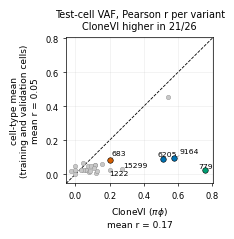

In [27]:
mut_clone = {m: k for k, ms in CARRIED.items() if k in HL for m in ms}   # coloured variants
fig, ax = plt.subplots(figsize=(1.9, 1.9))
ax.scatter(rec['CloneVI'], rec['cell-type mean'], s=10, c='#c8c8c8', edgecolor='#8a8a8a', lw=0.3, zorder=2)
for m, k in mut_clone.items():
    ax.scatter(rec.loc[m, 'CloneVI'], rec.loc[m, 'cell-type mean'], s=16, c=HL[k], edgecolor='k', lw=0.4, zorder=4)
lim = (min(rec.min().min(), 0) - 0.03, rec.max().max() + 0.05)
ax.plot(lim, lim, color='k', lw=0.6, ls='--', zorder=1)
ax.set_xlim(lim); ax.set_ylim(lim)
top5 = (rec['CloneVI'] - rec['cell-type mean']).sort_values(ascending=False).index[:5]
labelled = list(dict.fromkeys(list(mut_clone) + list(top5)))   # the coloured variants and the five where CloneVI gains most
texts = [ax.text(rec.loc[m, 'CloneVI'], rec.loc[m, 'cell-type mean'], m, fontsize=5.5) for m in labelled]
adjust_text(texts, x=rec['CloneVI'].to_numpy(), y=rec['cell-type mean'].to_numpy(), ax=ax,
            arrowprops=dict(arrowstyle='-', color='gray', lw=0.4), iter_lim=1000,   # iterations, not seconds: the same every run
            min_arrow_len=0)                                     # every label joined to its point by a line
ax.set_xlabel('CloneVI ($\\pi\\phi$)\nmean r = %.2f' % rec['CloneVI'].mean())
ax.set_ylabel('cell-type mean\n(training and validation cells)\nmean r = %.2f' % rec['cell-type mean'].mean())
ax.set_title(f'Test-cell VAF, Pearson r per variant\nCloneVI higher in {n_win}/{len(rec)}')
ax.grid(alpha=0.25, lw=0.4)
save(fig, 'fig3e_test_pearson')

## 7. Fig. 3f: which mutant-cell populations CloneVI captures

Definitions (Methods). For each variant, a cell is *covered* if its depth is at least 10, and *mutant* if in addition its VAF is at least 0.10 and at least three reads carry the alternate allele. Variants with at least 15 mutant and 15 non-mutant covered cells are analyzed.

- **Enrichment** (computed without the clonal probabilities): on a 30-nearest-neighbor graph of all cells (Euclidean distance on standardized $z$), the purity $u_m$ is the mean fraction of the neighbors of a mutant cell that are also mutant. The mutant labels are permuted 200 times among the covered cells to get the purity expected by chance $\mu_m$, and enrichment $= (u_m - \mu_m) / (1 - \mu_m)$: 0 for randomly placed mutant cells, 1 when all neighbors of mutant cells are mutant.
- **Capture**: the AUC with which the reconstructed VAF $\sum_k \pi_{ck}\phi_{km}$ (the six kept clones) ranks mutant above non-mutant covered cells.
- **Prevalence**: $\log_{10}$ of the number of mutant cells. **Heteroplasmy**: mean VAF of the mutant cells.

In [28]:
depth = den(adata_mg.X).astype(float)
alt = den(adata_mg.layers['all_mut'])
recon = np.asarray(adata_mg.obsm['pi_deleted']) @ np.asarray(adata_mg.varm['phi_deleted']).T   # reconstructed VAF from the kept clones, in the stored precision (float32)
z = np.asarray(adata_mg.obsm['z'])
z = (z - z.mean(0)) / np.maximum(z.std(0), 1e-9)
nn = NearestNeighbors(n_neighbors=31).fit(z).kneighbors(z, return_distance=False)[:, 1:]   # 30 neighbors, self removed
nn.shape

(9346, 30)

In [29]:
def capture_table(covered, mutant, n_perm=200, min_group=15, seed=0):
    rng = np.random.default_rng(seed)
    rows = []
    for j, m in enumerate(variants):
        cov, mut = covered[:, j], mutant[:, j]
        n_mut, n_non = int(mut.sum()), int((cov & ~mut).sum())
        row = dict(variant=m, n_mutant=n_mut, n_nonmutant=n_non, eligible=(n_mut >= min_group) and (n_non >= min_group))
        if row['eligible']:
            purity = mut[nn[mut]].mean()
            pool = np.flatnonzero(cov)
            null = np.empty(n_perm)
            for b in range(n_perm):                        # mutant labels permuted among the covered cells
                perm = np.zeros(len(mut), bool)
                perm[rng.choice(pool, n_mut, replace=False)] = True
                null[b] = perm[nn[perm]].mean()
            row.update(prevalence=np.log10(n_mut), heteroplasmy=vaf[mut, j].mean(), purity=purity,
                       null_purity=null.mean(), enrichment=(purity - null.mean()) / (1 - null.mean()),
                       auc=roc_auc_score(mut[cov], recon[cov, j]))
        rows.append(row)
    return pd.DataFrame(rows).set_index('variant')


covered = depth >= 10
cap_all = capture_table(covered, covered & (vaf >= 0.10) & (alt >= 3))
cap_all.assign(clone=cap_all.index.map(VARIANT_CLONE)).to_csv(f'{OUT}/fig3f_capture.csv')
cap_all[['n_mutant', 'n_nonmutant', 'eligible']].assign(clone=cap_all.index.map(VARIANT_CLONE))

,n_mutant,n_nonmutant,eligible,clone
variant,,,,
2593,139,3490,True,2.0
683,56,8728,True,1.0
6205,52,2617,True,3.0
9164,114,9184,True,3.0
3628,8,924,False,NaN
6185,18,2639,True,NaN
9321,39,7528,True,4.0
15140,6,2635,False,NaN
779,18,8716,True,5.0


The variants with enough mutant and non-mutant cells, and their properties:

In [30]:
cap = cap_all[cap_all['eligible']]
len(cap)

15

In [31]:
cap.drop(columns='eligible').assign(clone=cap.index.map(VARIANT_CLONE)).sort_values('enrichment', ascending=False).round(3)

,n_mutant,n_nonmutant,prevalence,heteroplasmy,purity,null_purity,enrichment,auc,clone
variant,,,,,,,,,
2593,139,3490,2.143,0.641,0.210,0.018,0.195,0.934,2.0
779,18,8716,1.255,0.955,0.165,0.002,0.163,0.999,5.0
9164,114,9184,2.057,0.980,0.164,0.012,0.153,0.981,3.0
6205,52,2617,1.716,0.971,0.069,0.008,0.061,0.975,3.0
9321,39,7528,1.591,0.962,0.038,0.004,0.034,0.932,4.0
15299,16,8740,1.204,0.851,0.021,0.002,0.019,0.113,NaN
683,56,8728,1.748,0.882,0.024,0.006,0.018,0.863,1.0
1222,22,5260,1.342,0.957,0.020,0.002,0.017,0.216,NaN
6185,18,2639,1.255,0.914,0.019,0.002,0.016,0.347,NaN


Spearman correlation of each property with the AUC, and the partial Spearman correlation adjusted for the other two properties (the Pearson correlation of the rank residuals after regressing out the ranks of the other two).

In [32]:
PROPS = ['prevalence', 'heteroplasmy', 'enrichment']


def partial_spearman(d, x, y, covs):
    C = np.column_stack([np.ones(len(d))] + [rankdata(d[c]) for c in covs])
    resid = lambda v: v - C @ np.linalg.lstsq(C, v, rcond=None)[0]
    return pearsonr(resid(rankdata(d[x])), resid(rankdata(d[y])))[0]


def correlations(d):
    return pd.DataFrame({'rho': [spearmanr(d[x], d['auc'])[0] for x in PROPS],
                         'partial rho': [partial_spearman(d, x, 'auc', [c for c in PROPS if c != x]) for x in PROPS]},
                        index=PROPS)


corr = correlations(cap)
corr.to_csv(f'{OUT}/fig3f_correlations.csv')
corr.round(3)

,rho,partial rho
prevalence,0.594,0.173
heteroplasmy,0.314,0.322
enrichment,0.671,0.552


Prevalence is itself correlated with enrichment, which is why its correlation with the AUC drops after adjustment (from +0.59 to +0.17; the mean VAF keeps a partial correlation of +0.32):

In [33]:
round(spearmanr(cap['prevalence'], cap['enrichment'])[0], 3)

0.602

The AUC of the variants of Clones 1, 3 and 5, and of the variants with almost no enrichment (below 0.01):

In [34]:
shown = cap.loc[[m for m in mut_clone if m in cap.index], ['enrichment', 'auc']].assign(clone=lambda d: d.index.map(mut_clone))
low = cap.loc[cap['enrichment'] < 0.01, ['enrichment', 'auc']]
shown.round(3), low.round(3)

(         enrichment    auc  clone
 variant                          
 683           0.018  0.863      1
 6205          0.061  0.975      3
 9164          0.153  0.981      3
 779           0.163  0.999      5,
          enrichment    auc
 variant                   
 10158         0.003  0.222
 15812         0.010  0.266
 11864         0.007  0.502
 9753          0.007  0.315
 8697          0.010  0.669)

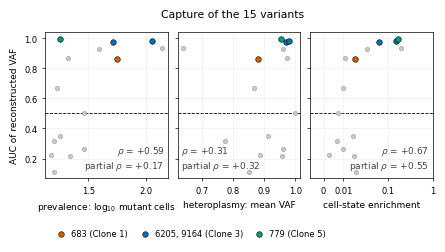

In [35]:
XLAB = {'prevalence': 'prevalence: log$_{10}$ mutant cells', 'heteroplasmy': 'heteroplasmy: mean VAF',
        'enrichment': 'cell-state enrichment'}
fig, axes = plt.subplots(1, 3, figsize=(5.0, 1.9), sharey=True, gridspec_kw={'wspace': 0.08})
for ax, x in zip(axes, PROPS):
    rest = cap[~cap.index.isin(list(mut_clone))]
    ax.scatter(rest[x], rest['auc'], s=10, c='#c8c8c8', edgecolor='#8a8a8a', lw=0.3, zorder=2)
    for k in HL:
        ms = CARRIED[k]
        h = cap.loc[[m for m in ms if m in cap.index]]
        ax.scatter(h[x], h['auc'], s=16, c=HL[k], edgecolor='k', lw=0.4, zorder=4, label=f'{", ".join(ms)} (Clone {k})')
    ax.axhline(0.5, color='k', lw=0.6, ls='--', zorder=1)
    if x == 'enrichment':
        ax.set_xscale('symlog', linthresh=0.01, linscale=0.4)
        ax.set_xticks([0, 0.01, 0.1, 1]); ax.set_xticklabels(['0', '0.01', '0.1', '1'])
    ax.set_xlabel(XLAB[x])
    ax.grid(alpha=0.25, lw=0.4)
    # rho and partial rho in the corner farthest from the points
    fig.canvas.draw()
    pts = ax.transAxes.inverted().transform(ax.transData.transform(np.c_[cap[x], cap['auc']]))
    corners = {(0.97, 0.04): ('right', 'bottom'), (0.03, 0.04): ('left', 'bottom'), (0.97, 0.96): ('right', 'top'),
               (0.03, 0.96): ('left', 'top')}
    best = max(corners, key=lambda c: np.min(np.hypot(pts[:, 0] - c[0], (pts[:, 1] - c[1]) * 1.5)))
    ax.text(*best, f'$\\rho$ = {corr.loc[x, "rho"]:+.2f}\npartial $\\rho$ = {corr.loc[x, "partial rho"]:+.2f}',
            transform=ax.transAxes, ha=corners[best][0], va=corners[best][1], color='#444')
axes[0].set_ylabel('AUC of reconstructed VAF')
axes[0].legend(loc='upper left', bbox_to_anchor=(0, -0.3), ncol=3, frameon=False, handletextpad=0.2, columnspacing=1.0)
fig.suptitle(f'Capture of the {len(cap)} variants', y=1.0)
save(fig, 'fig3f_capture')

### Sensitivity analysis (Methods)

The same correlations without the requirement of three alternate reads.

In [36]:
cap_alt1_all = capture_table(covered, covered & (vaf >= 0.10))
cap_alt1_all.assign(clone=cap_alt1_all.index.map(VARIANT_CLONE)).to_csv(f'{OUT}/capture_without_alt3.csv')
cap_alt1 = cap_alt1_all[cap_alt1_all['eligible']]
cap_alt1.drop(columns='eligible').assign(clone=cap_alt1.index.map(VARIANT_CLONE)).sort_values('enrichment', ascending=False).round(3)

,n_mutant,n_nonmutant,prevalence,heteroplasmy,purity,null_purity,enrichment,auc,clone
variant,,,,,,,,,
2593,149,3480,2.173,0.606,0.197,0.019,0.181,0.908,2.0
779,18,8716,1.255,0.955,0.165,0.002,0.163,0.999,5.0
9164,114,9184,2.057,0.980,0.164,0.012,0.154,0.981,3.0
6205,54,2615,1.732,0.939,0.066,0.008,0.058,0.943,3.0
9321,40,7527,1.602,0.940,0.038,0.004,0.033,0.910,4.0
683,56,8728,1.748,0.882,0.024,0.006,0.018,0.863,1.0
6185,19,2638,1.279,0.871,0.018,0.003,0.015,0.363,NaN
1222,25,5257,1.398,0.855,0.017,0.003,0.015,0.271,NaN
8697,17,9232,1.230,0.866,0.012,0.002,0.010,0.669,NaN


In [37]:
corr_alt1 = correlations(cap_alt1)
corr_alt1.to_csv(f'{OUT}/correlations_without_alt3.csv')
len(cap_alt1), corr_alt1.round(3)

(16,
                 rho  partial rho
 prevalence    0.459        0.298
 heteroplasmy  0.365        0.152
 enrichment    0.709        0.568)

## 8. Supplementary Fig. S3

### a. Clonal probabilities of the six kept clones

The maps `pi_clone0` to `pi_clone5` of section 4.

### b. The 30 genes with the highest $\pi$-weighted mean expression $s_{gk}$ in each clone

In [38]:
top30 = pd.DataFrame({f'Clone {k}': s_gk[k].sort_values(ascending=False).head(30).index for k in range(pi.shape[1])})
top30.to_csv(f'{OUT}/supfig3b_top30_genes.csv', index=False)
top30

,Clone 0,Clone 1,Clone 2,Clone 3,Clone 4,Clone 5
0,ZNF860,TRDV1,GATA2,TRBV7-9,TRGV8,TRDV2
1,COL19A1,BOK,ANGPT1,TNIP3,HMCN2,KLRC1
2,EBF1,TRBV12-3,ERG,RGS1,HOXB9,TRGC1
3,PAX5,TRAV38-2DV8,EGFL7,GZMK,TRGV11,ME1
4,SOX5,ZNF80,APOE,CXCR6,TRAV30,IRGM
5,VPREB3,NUAK1,EPCAM,TRBV29-1,TRGV10,ZBTB16
6,CD19,EFNA5,ZNF385D,TIMD4,DKK2,TRDC
7,GNG8,VSTM2B,APOC1,TRAV5,GATA6,IL18RAP
8,GREM2,KIFC3,SMIM24,TNFRSF9,NLRP7,ACSM1
9,PI16,TRGV9,SPTA1,CCR5,RAI14,SLC4A10


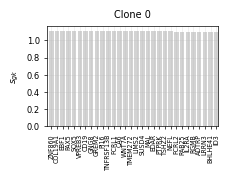

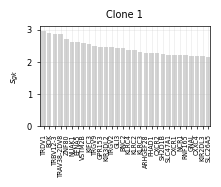

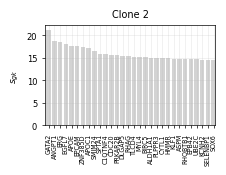

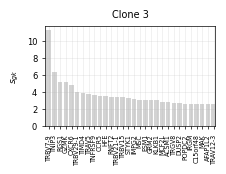

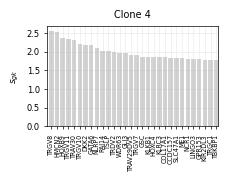

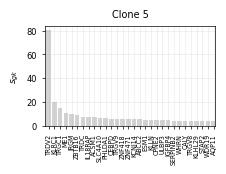

In [39]:
for k in range(pi.shape[1]):
    top = s_gk[k].sort_values(ascending=False).head(30)
    fig, ax = plt.subplots(figsize=(2.2, 1.3))
    ax.bar(range(30), top.to_numpy(), color='lightgray')
    ax.set_xticks(range(30))
    ax.set_xticklabels(top.index, rotation=90, fontsize=4.5)
    ax.set_xlim(-0.7, 29.3)
    ax.set_ylabel(r'$s_{gk}$')
    ax.set_title(f'Clone {k}')
    ax.grid(alpha=0.3, lw=0.4)
    save(fig, f'supfig3b_top30_clone{k}')

### c. $\pi$-weighted mean of the observed VAF and $\phi$, for each variant and clone

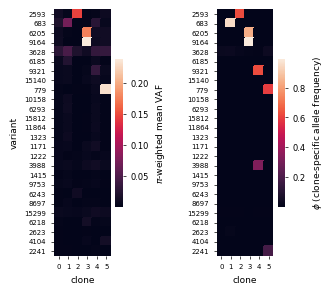

In [40]:
vaf_pi = (vaf.T @ pi) / pi.sum(0)
fig, axes = plt.subplots(1, 2, figsize=(3.2, 3.2), gridspec_kw={'wspace': 0.9})
for ax, val, lab in [(axes[0], vaf_pi, r'$\pi$-weighted mean VAF'), (axes[1], phi, r'$\phi$ (clone-specific allele frequency)')]:
    sns.heatmap(val, square=True, ax=ax, linewidths=0.3, linecolor='face', yticklabels=variants,
                cbar_kws={'label': lab, 'shrink': 0.6})
    ax.set_xlabel('clone')
    ax.tick_params(length=2, labelsize=5)
axes[0].set_ylabel('variant')
save(fig, 'supfig3c_vaf_pi_and_phi')

## 9. The numbers in the paper

Every number of the MAESTER analysis quoted in the paper, next to the value computed above. `where` names the part of the paper: the Results section, a figure legend or alt text, a supplementary table or the Methods subsection.

In [41]:
f2 = lambda x: f'{x:+.2f}'
shown_auc = shown['auc']
K683, K9164, K779 = (VARIANT_CLONE[m] for m in ('683', '9164', '779'))
R, T2 = 'Results (MAESTER)', 'Supp. Table 2'
rows = [('variants', f'{R}; Methods (Processing of MAESTER and CLL mutation data); {T2}', '26', str(len(variants))),
        ('kept clones', f'{R}; Supp. Fig. S3 legend', '6', str(pi.shape[1])),
        ('clones carrying a variant (phi > 0.2)', R, '1, 2, 3, 4, 5', ', '.join(str(k) for k in sorted(CARRIED))),
        ('clones of 683, 9164 and 779 (Fig. 3c)', f'{R}; Fig. 3 legend', '1, 3, 5', f'{K683}, {K9164}, {K779}'),
        ('TCR gene of Clone 3', f'{R}; Supp. Fig. S3 legend; Fig. 3 alt text', 'TRBV7-9', TCR_GENE[K9164]),
        ('TCR gene of Clone 5', f'{R}; Supp. Fig. S3 legend; Fig. 3 alt text', 'TRDV2', TCR_GENE[K779]),
        ('TCR gene of Clone 1 (Fig. 3d)', 'Fig. 3 alt text', 'TRDV1', TCR_GENE[K683]),
        ('top three TCR genes of Clone 1', 'Supp. Fig. S3 legend', 'TRDV1, TRBV12-3, TRAV38-2DV8',
         ', '.join(s_gk.loc[is_tcr_v, K683].sort_values(ascending=False).index[:3])),
        ('largest pi of Clone 1', R, '0.15', f'{pi[:, K683].max():.2f}'),
        ('variants where CloneVI is higher', R, '21 of 26', f'{n_win} of {len(rec)}'),
        ('mean Pearson r, CloneVI', R, '0.17', f'{rec["CloneVI"].mean():.2f}'),
        ('mean Pearson r, cell-type mean', R, '0.05', f'{rec["cell-type mean"].mean():.2f}'),
        ('variants analyzed for capture', f'{R}; Fig. 3 legend', '15', str(len(cap))),
        ('rho, enrichment', R, '+0.67', f2(corr.loc['enrichment', 'rho'])),
        ('rho, prevalence', R, '+0.59', f2(corr.loc['prevalence', 'rho'])),
        ('rho, prevalence vs enrichment', R, '+0.60', f2(spearmanr(cap['prevalence'], cap['enrichment'])[0])),
        ('partial rho, enrichment', R, '+0.55', f2(corr.loc['enrichment', 'partial rho'])),
        ('partial rho, prevalence', R, '+0.17', f2(corr.loc['prevalence', 'partial rho'])),
        ('partial rho, mean VAF', R, '+0.32', f2(corr.loc['heteroplasmy', 'partial rho'])),
        ('AUC, variants of Clones 1, 3, 5', R, '0.86-1.00', f'{shown_auc.min():.2f}-{shown_auc.max():.2f}'),
        ('variants with enrichment below 0.01', R, '5', str(len(low))),
        ('their AUC', R, '0.22-0.67', f'{low["auc"].min():.2f}-{low["auc"].max():.2f}'),
        ('without the alt-read requirement: partial rho, enrichment', 'Methods (Cell-state enrichment and capture)', '+0.57',
         f2(corr_alt1.loc['enrichment', 'partial rho'])),
        ('without the alt-read requirement: partial rho of prevalence and mean VAF', 'Methods (Cell-state enrichment and capture)', 'positive',
         'positive' if (corr_alt1.loc[['prevalence', 'heteroplasmy'], 'partial rho'] > 0).all() else 'not positive'),
        ('model input genes', 'Methods (Preprocessing of MAESTER gene expression data)', '2,000', f'{params["adata_shape"][1]:,}'),
        ('downstream genes', 'Methods (Preprocessing of MAESTER gene expression data)', '4,000', f'{adata.n_vars:,}'),
        ('K', f'{T2}; Methods (Pruning of clones)', '20', str(params['model_params']['k'])),
        ('validation / test fraction', 'Methods (Loss function)', '0.05 / 0.1', f'{params["val_ratio"]} / {params["test_ratio"]}'),
        ('sample indicator', T2, 'none', 'none' if not params['use_multisamples'] else 'used'),
        ('decomposition of phi', T2, 'no', 'yes' if params['model_params'].get('use_phi_common', True) else 'no'),
        ('regularization', T2, 'none', 'none' if not params['use_sparse_term'] else 'used')]
numbers = pd.DataFrame(rows, columns=['item', 'where', 'paper', 'computed'])
numbers['match'] = numbers['paper'] == numbers['computed']
numbers.to_csv(f'{OUT}/numbers.csv', index=False)
pd.set_option('display.max_colwidth', 80)
numbers

,item,where,paper,computed,match
0,variants,Results (MAESTER); Methods (Processing of MAESTER and CLL mutation data); Su...,26,26,True
1,kept clones,Results (MAESTER); Supp. Fig. S3 legend,6,6,True
2,clones carrying a variant (phi > 0.2),Results (MAESTER),"1, 2, 3, 4, 5","1, 2, 3, 4, 5",True
3,"clones of 683, 9164 and 779 (Fig. 3c)",Results (MAESTER); Fig. 3 legend,"1, 3, 5","1, 3, 5",True
4,TCR gene of Clone 3,Results (MAESTER); Supp. Fig. S3 legend; Fig. 3 alt text,TRBV7-9,TRBV7-9,True
5,TCR gene of Clone 5,Results (MAESTER); Supp. Fig. S3 legend; Fig. 3 alt text,TRDV2,TRDV2,True
6,TCR gene of Clone 1 (Fig. 3d),Fig. 3 alt text,TRDV1,TRDV1,True
7,top three TCR genes of Clone 1,Supp. Fig. S3 legend,"TRDV1, TRBV12-3, TRAV38-2DV8","TRDV1, TRBV12-3, TRAV38-2DV8",True
8,largest pi of Clone 1,Results (MAESTER),0.15,0.15,True
9,variants where CloneVI is higher,Results (MAESTER),21 of 26,21 of 26,True


Items that do not match:

In [42]:
numbers[~numbers['match']]

,item,where,paper,computed,match


## 10. Fig. 3

The panels above, drawn as one figure at the text width (505.7 pt) and printed without scaling. The layout follows the rules of Fig. 4 (`03e_cll_figure4.ipynb`): the positions are decided first from sizes shared by all figures, and each panel is drawn into its axes by the standard functions. All maps have the same size (the UMAP undistorted), each with its colorbar on the right; panel letters stand in the letter column at the left of their panel, on the top line of the titles.

a, the cell types; only the T cells (T cell, CTL), to which the text refers, are named on the map, and the legend of all cell types is in Supplementary Fig. S3a. b, $\phi$, centred below a (square cells). c, d, Clones 1, 3 and 5 (683, 6205 + 9164, 779). e, f, four scatter plots of one size, one per column. Titles say what a panel shows, not its result; the correlations of f (Spearman and partial Spearman) are written in its plots.

In [43]:
# sizes shared by all figures (points), as in 03e_cll_figure4.ipynb
W = 505.69                          # text width
M = 1                               # outer margin, so that frames at the edge are drawn whole
MB = 4                              # bottom margin below a map: half of its lowest colorbar label hangs below it
LG = 9                              # letter column at the left of every column (the gap between columns)
CL = 3                              # clearance at the right of a panel that has no colorbar beside it
GY = 6                              # gap between rows
T = 11                              # title row above a panel; titles and letters stand on its baseline
PAD = 3                             # baseline of the titles above the axes
CB_W, CB_PAD, CB_ROOM = 4, 3, 26    # colorbar beside a map: width, distance, and the room it takes with its labels
SW = (W - 2 * M) / 4                # width of a column (4 columns), letter column included
MW = SW - LG - CB_ROOM              # width of a map
LH = 1.2 * plt.rcParams['axes.titlesize']   # height of a line of a title
plt.rcParams['axes.titlepad'] = PAD

.../site-packages/scanpy/plotting/_tools/scatterplots.py:1216: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
.../site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


figure 505.69 x 465.3 pt; maps 90.9 x 92.3 pt (point size 1.62); b cells 7.0 pt; scatter plots 79.9 pt


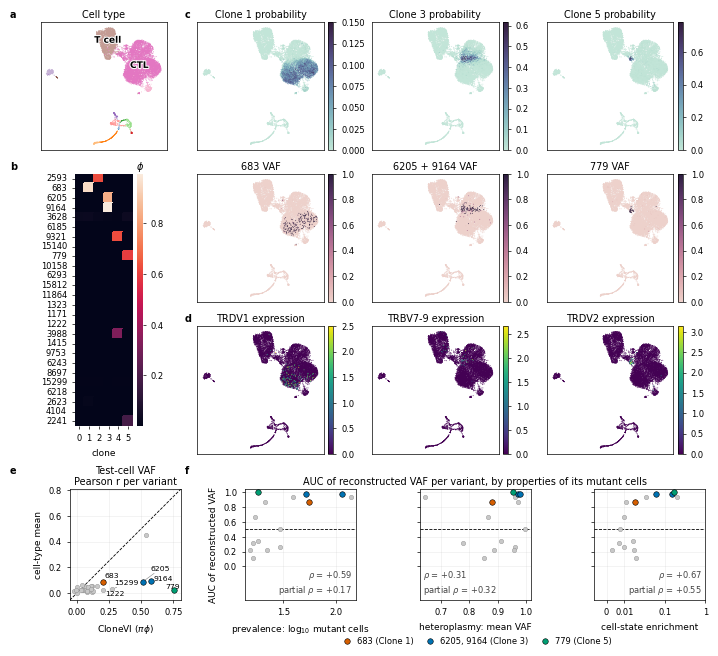

In [44]:
# one table of cells for the maps: the CloneVI UMAP and the values drawn
cells = sc.AnnData(obs=pd.DataFrame(index=np.arange(len(xy)).astype(str)))
cells.obsm['X_umap'] = np.asarray(xy)
cells.obs['Cell type'] = pd.Categorical(celltype, categories=cats)
for k in HL:
    cells.obs[f'Clone {k} probability'] = pi[:, k]
    J = [list(variants).index(m) for m in CARRIED[k]]
    cells.obs[' + '.join(CARRIED[k]) + ' VAF'] = vaf[:, J].mean(1)
    cells.obs[f'{TCR_GENE[k]} expression'] = den(expr[:, TCR_GENE[k]].X).ravel()

MH = MW * np.ptp(xy[:, 1]) / np.ptp(xy[:, 0])
SIZE = 1.8 * MW * MH / len(xy)                       # point size: the points cover 1.8 times the area of a map
col = lambda j: M + j * SW
RH = T + MH + GY                                     # a row of maps
row = [M + i * RH for i in range(4)]                 # rows 0-2: a and b (column 0), c and d (columns 1-3); row 3: e, f
L2 = 34                                              # y labels of the scatter plots (two lines) and their ticks
FW = SW - LG - L2 - CL                               # a scatter plot: width and height
T2 = T + LH                                          # title row of row 3 (two lines, e); letters on its top line
BX = lambda n: 2 + 3.5 + 1.2 * 6 + 4 + n * 1.2 * 6.5 # below a scatter plot: ticks, tick labels and an n-line x label
y_sc = row[3] + T2

def legend_height(**kw):
    f = plt.figure(figsize=(W / 72, 3))
    b = f.legend(**kw).get_window_extent(f.canvas.get_renderer())
    plt.close(f)
    return b.height * 72 / f.dpi

LEG = dict(frameon=False, handletextpad=0.2, columnspacing=1.0, borderaxespad=0, borderpad=0)
leg_f = dict(handles=[Line2D([], [], marker='o', ls='', markersize=4, markerfacecolor=HL[k], markeredgecolor='k',
                             markeredgewidth=0.4, label=f'{", ".join(CARRIED[k])} (Clone {k})') for k in HL], ncol=3, **LEG)
y_lf = y_sc + FW + BX(1) + 2
H = y_lf + legend_height(**leg_f) + MB
fig = plt.figure(figsize=(W / 72, H / 72))

def axes(x, y, w, h):
    return fig.add_axes([x / W, 1 - (y + h) / H, w / W, h / H])

def letter(x, y, s):                                 # on the top line of the title row at y, in the letter column at x
    fig.text(x / W, 1 - (y + T - PAD) / H, s, fontweight='bold', fontsize=plt.rcParams['axes.titlesize'], va='baseline')

emb = dict(basis='umap', show=False, frameon=True, size=SIZE, colorbar_loc=None)
def umap(x, y, color, **kw):
    ax = axes(x, y + T, MW, MH)
    sc.pl.embedding(cells, color=color, ax=ax, **emb, **kw)
    ax.set_xlabel(''); ax.set_ylabel('')
    if 'cmap' in kw:
        fig.colorbar(ax.collections[0], cax=axes(x + MW + CB_PAD, y + T, CB_W, MH))
    return ax

# a: only the T cells are named, on the map (the legend of all cell types is in Supplementary Fig. S3a)
cx = col(0) + LG + (SW - LG) / 2
letter(col(0), row[0], 'a')
ax = umap(cx - MW / 2, row[0], 'Cell type', palette=[ct_col[c] for c in cats], legend_loc=None)
for g in ('T cell', 'CTL'):
    x_, y_ = np.median(xy[celltype == g], axis=0)
    ax.text(x_, y_, g, ha='center', va='center', fontweight='bold', path_effects=[pe.withStroke(linewidth=1.5, foreground='white')])

# b: square cells, between the variant names and the colorbar, below a down to the scatter plots
letter(col(0), row[1], 'b')
L, B = 26, 20
y0 = row[1] + T
n_var, n_clone = phi.shape
cell = min(2 * min(cx - col(0) - LG - L, col(1) - CB_ROOM - cx) / n_clone, (row[3] - GY - B - y0) / n_var)
hw, hh = n_clone * cell, n_var * cell
ax = axes(cx - hw / 2, y0, hw, hh)
cax = axes(cx + hw / 2 + CB_PAD, y0, CB_W, hh)
sns.heatmap(pd.DataFrame(phi, index=variants), ax=ax, square=True, linewidths=0.3, linecolor='face', xticklabels=True,
            yticklabels=True, cbar_ax=cax)
cax.set_title(r'$\phi$')
ax.set_xlabel('clone')

# c, d
letter(col(1), row[0], 'c')
letter(col(1), row[2], 'd')
for j, k in enumerate(HL):
    umap(col(1 + j) + LG, row[0], f'Clone {k} probability', cmap=PI_CMAP, vmin=0)
    umap(col(1 + j) + LG, row[1], ' + '.join(CARRIED[k]) + ' VAF', cmap=VAF_CMAP, vmin=0)
    v = cells.obs[f'{TCR_GENE[k]} expression'].to_numpy()
    umap(col(1 + j) + LG, row[2], f'{TCR_GENE[k]} expression', cmap=EXPR_CMAP, vmin=0, vmax=np.quantile(v[v > 0], 0.99))

# e
letter(col(0), row[3], 'e')
ax = axes(col(0) + LG + L2, y_sc, FW, FW)
ax.scatter(rec['CloneVI'], rec['cell-type mean'], s=10, c='#c8c8c8', edgecolor='#8a8a8a', lw=0.3, zorder=2)
for m, k in mut_clone.items():
    ax.scatter(rec.loc[m, 'CloneVI'], rec.loc[m, 'cell-type mean'], s=16, c=HL[k], edgecolor='k', lw=0.4, zorder=4)
lim = (min(rec.min().min(), 0) - 0.03, rec.max().max() + 0.05)
ax.plot(lim, lim, color='k', lw=0.6, ls='--', zorder=1)
ax.set_xlim(lim); ax.set_ylim(lim)
top5 = (rec['CloneVI'] - rec['cell-type mean']).sort_values(ascending=False).index[:5]
labelled = list(dict.fromkeys(list(mut_clone) + list(top5)))   # the coloured variants and the five where CloneVI gains most
texts = [ax.text(rec.loc[m, 'CloneVI'], rec.loc[m, 'cell-type mean'], m, fontsize=5.5) for m in labelled]
adjust_text(texts, x=rec['CloneVI'].to_numpy(), y=rec['cell-type mean'].to_numpy(), ax=ax,
            arrowprops=dict(arrowstyle='-', color='gray', lw=0.4), iter_lim=1000,   # iterations, not seconds: the same every run
            min_arrow_len=0)                                     # every label joined to its point by a line
ax.set_xlabel('CloneVI ($\\pi\\phi$)')
ax.set_ylabel('cell-type mean')
ax.set_title('Test-cell VAF\nPearson r per variant')
ax.grid(alpha=0.25, lw=0.4)

# f
letter(col(1), row[3], 'f')
fax = [axes(col(1 + j) + LG + L2, y_sc, FW, FW) for j in range(3)]
for ax, x in zip(fax, PROPS):
    rest = cap[~cap.index.isin(list(mut_clone))]
    ax.scatter(rest[x], rest['auc'], s=10, c='#c8c8c8', edgecolor='#8a8a8a', lw=0.3, zorder=2)
    for k in HL:
        h = cap.loc[[m for m in CARRIED[k] if m in cap.index]]
        ax.scatter(h[x], h['auc'], s=16, c=HL[k], edgecolor='k', lw=0.4, zorder=4)
    ax.axhline(0.5, color='k', lw=0.6, ls='--', zorder=1)
    if x == 'enrichment':
        ax.set_xscale('symlog', linthresh=0.01, linscale=0.4)
        ax.set_xticks([0, 0.01, 0.1, 1]); ax.set_xticklabels(['0', '0.01', '0.1', '1'])
    ax.set_xlabel(XLAB[x])
    ax.grid(alpha=0.25, lw=0.4)
lo, hi = min(a.get_ylim()[0] for a in fax), max(a.get_ylim()[1] for a in fax)
ticks = [v for v in fax[0].get_yticks() if 0 <= v <= 1]   # AUC ticks only (the band below holds no values)
for ax, x in zip(fax, PROPS):
    ax.set_ylim(lo, hi)
    ax.set_yticks(ticks)
    if ax is not fax[0]:
        ax.tick_params(labelleft=False)
fax[0].set_ylabel('AUC of reconstructed VAF')
# rho and partial rho in each plot (not in the titles), at the bottom: the y range of the three plots is extended
# downwards by the height of the two lines, so that a band without points holds them; of its two corners, the one
# farther from the points
fig.canvas.draw()                                    # the axis limits are final only after drawing
renderer = fig.canvas.get_renderer()
label = lambda x: f'$\\rho$ = {corr.loc[x, "rho"]:+.2f}\npartial $\\rho$ = {corr.loc[x, "partial rho"]:+.2f}'
t = fax[0].text(0, 0, label(PROPS[0]), transform=fax[0].transAxes, fontsize=plt.rcParams['legend.fontsize'])
f_text = (t.get_window_extent(renderer).height + 6) / fax[0].get_window_extent(renderer).height   # with 3 px above and below
t.remove()
lo, hi = fax[0].get_ylim()
lo = lo - (hi - lo) * f_text / (1 - f_text)
CORNERS = {(0.97, 0.03): 'right', (0.03, 0.03): 'left'}
ticks = [v for v in fax[0].get_yticks() if 0 <= v <= 1]   # AUC ticks only (the band below holds no values)
for ax, x in zip(fax, PROPS):
    ax.set_ylim(lo, hi)
    ax.set_yticks(ticks)
    pa = ax.transAxes.inverted().transform(ax.transData.transform(np.c_[cap[x], cap['auc']]))
    best = max(CORNERS, key=lambda c: np.min(np.hypot(pa[:, 0] - c[0], (pa[:, 1] - c[1]) * 1.5)))
    ax.text(*best, label(x), transform=ax.transAxes, ha=CORNERS[best], va='bottom', color='#444',
            fontsize=plt.rcParams['legend.fontsize'])
fx0, fx1 = col(1) + LG + L2, col(3) + LG + L2 + FW
fig.text((fx0 + fx1) / 2 / W, 1 - (y_sc - PAD) / H, 'AUC of reconstructed VAF per variant, by properties of its mutant cells', ha='center', va='baseline',
         fontsize=plt.rcParams['axes.titlesize'])
fig.legend(loc='upper center', bbox_to_anchor=((fx0 + fx1) / 2 / W, 1 - y_lf / H), **leg_f)

fig.savefig(f'{OUT}/figure3.pdf')
fig.savefig(f'{OUT}/figure3.png', dpi=300)
print(f'figure {W} x {H:.1f} pt; maps {MW:.1f} x {MH:.1f} pt (point size {SIZE:.2f}); b cells {cell:.1f} pt; scatter plots {FW:.1f} pt')

## 11. Supplementary Fig. S3

The panels of section 8 as one figure, with the sizes of Fig. 3 (section 10), each panel in its own rows: a, the cell types of Fig. 3a with the legend of all of them; b, the six maps of $\pi$ (four per row); c, the bar plots, three per row (gene names at 5 pt, as the 30 names must fit); d, the two heatmaps side by side, with the clones as rows and the variants as columns.

.../site-packages/scanpy/plotting/_tools/scatterplots.py:1216: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
.../site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


figure 505.69 x 629.5 pt; maps 90.9 x 92.3 pt; d cells 7.6 pt


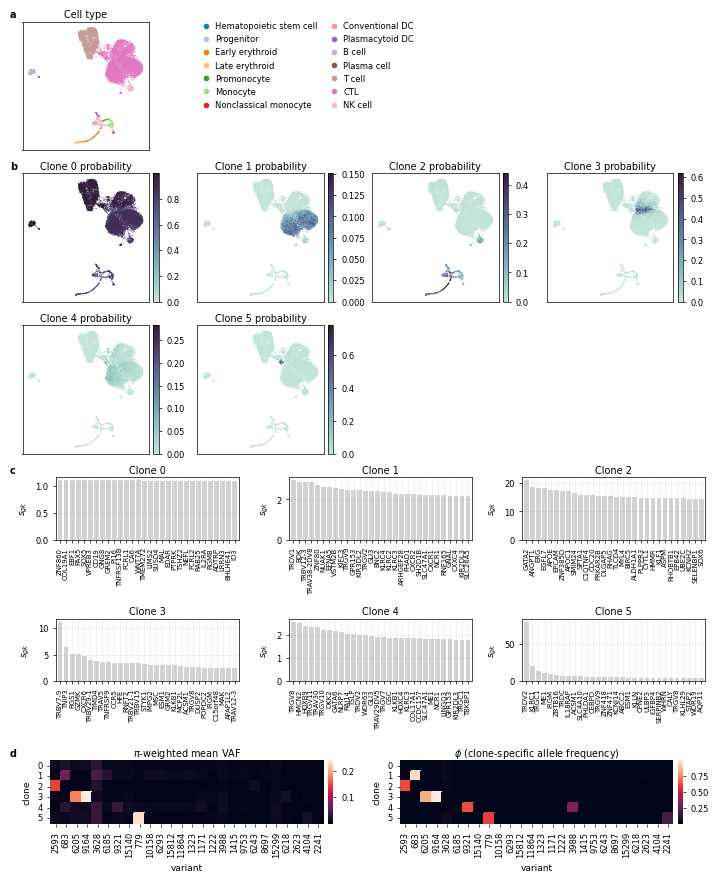

In [45]:
# the maps of a and b: the cell types and the clonal probabilities of the six kept clones
cells = sc.AnnData(obs=pd.DataFrame(index=np.arange(len(xy)).astype(str)))
cells.obsm['X_umap'] = np.asarray(xy)
nk = pi.shape[1]
cells.obs['Cell type'] = pd.Categorical(celltype, categories=cats)
for k in range(nk):
    cells.obs[f'Clone {k} probability'] = pi[:, k]
vaf_pi = (vaf.T @ pi) / pi.sum(0)                    # pi-weighted mean VAF, variants x clones (as in section 8c)

MH = MW * np.ptp(xy[:, 1]) / np.ptp(xy[:, 0])
SIZE = 1.8 * MW * MH / len(xy)
col = lambda j: M + j * SW
# each panel in its own rows: a (the cell types, with their legend), b (the maps of pi, four per row), c (the bar plots,
# three per row), d (the two heatmaps side by side, clones as rows and variants as columns)
NB = 30
L1 = 24                                              # y labels of c
BH = 45                                              # height of a bar plot
BG = 40                                              # below a bar plot: the gene names (5 pt)
LC = 20                                              # y labels of d (clone numbers, 'clone')
BC = 36                                              # below d: the variant names and 'variant'
SW3 = (W - 2 * M) / 3                                # slot of a bar plot (three per row)
ccell = (2 * SW - LG - LC - CB_ROOM) / len(variants)  # cells of d, as wide as two columns allow
RA, RC = T + MH + GY, T + BH + BG + GY               # heights of a row of maps and of bar plots
nb, nc = -(-nk // 4), -(-nk // 3)                    # rows of b and of c
y_b = M + RA
y_c = y_b + nb * RA
y_d = y_c + nc * RC
H = y_d + T + nk * ccell + BC + MB
fig = plt.figure(figsize=(W / 72, H / 72))

def axes(x, y, w, h):
    return fig.add_axes([x / W, 1 - (y + h) / H, w / W, h / H])

def letter(x, y, s):
    fig.text(x / W, 1 - (y + T - PAD) / H, s, fontweight='bold', fontsize=plt.rcParams['axes.titlesize'], va='baseline')

emb = dict(basis='umap', show=False, frameon=True, size=SIZE, colorbar_loc=None)
def umap(x, y, color, **kw):
    ax = axes(x, y + T, MW, MH)
    sc.pl.embedding(cells, color=color, ax=ax, **emb, **kw)
    ax.set_xlabel(''); ax.set_ylabel('')
    if 'cmap' in kw:
        fig.colorbar(ax.collections[0], cax=axes(x + MW + CB_PAD, y + T, CB_W, MH))
    return ax

# a: the cell types of Fig. 3a, with the legend of all of them beside the map
letter(col(0), M, 'a')
umap(col(0) + LG, M, 'Cell type', palette=[ct_col[c] for c in cats], legend_loc=None)
fig.legend(handles=[Line2D([], [], marker='o', ls='', markersize=3, color=ct_col[c], label=c) for c in cats], ncol=2,
           loc='upper left', bbox_to_anchor=((col(1) + LG) / W, 1 - (M + T) / H), frameon=False, handletextpad=0.1,
           columnspacing=1.0, borderaxespad=0, borderpad=0)

# b
letter(col(0), y_b, 'b')
for k in range(nk):
    umap(col(k % 4) + LG, y_b + (k // 4) * RA, f'Clone {k} probability', cmap=PI_CMAP, vmin=0)

# c
letter(col(0), y_c, 'c')
for k in range(nk):
    x, y = M + (k % 3) * SW3, y_c + (k // 3) * RC
    top = s_gk[k].sort_values(ascending=False).head(NB)
    ax = axes(x + LG + L1, y + T, SW3 - LG - L1 - CL, BH)
    ax.bar(range(NB), top.to_numpy(), color='lightgray')
    ax.set_xticks(range(NB))
    ax.set_xticklabels(top.index, rotation=90, fontsize=5)
    ax.set_xlim(-0.7, NB - 0.3)
    ax.set_ylabel(r'$s_{gk}$')
    ax.set_title(f'Clone {k}')
    ax.grid(alpha=0.3, lw=0.4)

# d: the pi-weighted mean VAF and phi
letter(col(0), y_d, 'd')
for i, (val, ttl) in enumerate([(vaf_pi, r'$\pi$-weighted mean VAF'), (phi, r'$\phi$ (clone-specific allele frequency)')]):
    x = col(2 * i) + LG + LC
    ax = axes(x, y_d + T, len(variants) * ccell, nk * ccell)
    cax = axes(x + len(variants) * ccell + CB_PAD, y_d + T, CB_W, nk * ccell)
    sns.heatmap(pd.DataFrame(val.T, columns=variants), ax=ax, square=True, linewidths=0.3, linecolor='face',
                xticklabels=True, yticklabels=True, cbar_ax=cax)
    ax.set_ylabel('clone')
    ax.set_xlabel('variant')
    ax.tick_params(axis='y', rotation=0)
    ax.set_title(ttl)

fig.savefig(f'{OUT}/supfig3.pdf')
fig.savefig(f'{OUT}/supfig3.png', dpi=300)
print(f'figure {W} x {H:.1f} pt; maps {MW:.1f} x {MH:.1f} pt; d cells {ccell:.1f} pt')